<a href="https://colab.research.google.com/github/Xen-04/Portafolio_Mineria_de-_datos/blob/main/02_8_regresion_lineal/lab_3_regresion_lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 03 · Regresión lineal simple y múltiple

**Foco:** no «¿qué tan alto es mi R²?», sino «¿puedo confiar en este modelo y explicar por qué?»

- **Bloque 1:** regresión simple con Breast Cancer Wisconsin (Diagnostic)
- **Bloque 2:** regresión múltiple con EA Sports FC 24 (Complete Player Dataset)
- **Bloque 3:** transferencia a mi dataset del Laboratorio 01, Data Science for COVID-19 (DS4C · PatientInfo), con variable objetivo dias_a_alta.

In [ ]:
!pip install -q -U kagglehub

# Bloque 1 · Regresión lineal simple (Breast Cancer)

## 1.1 Carga e inspección

In [41]:
path_bc = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print(os.listdir(path_bc))   # confirmar cuál es el CSV principal

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
['data.csv']


In [42]:
csv_bc = [f for f in os.listdir(path_bc) if f.endswith(".csv")][0]
bc = pd.read_csv(os.path.join(path_bc, csv_bc))
print("Dimensiones:", bc.shape)
print(bc.dtypes.value_counts())
print("\nColumnas con nulos:")
print(bc.isna().sum()[bc.isna().sum() > 0])
bc.head()

Dimensiones: (569, 33)
float64    31
int64       1
object      1
Name: count, dtype: int64

Columnas con nulos:
Unnamed: 32    569
dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
# Columnas que no son mediciones: id (identificador), diagnosis (etiqueta) y 'Unnamed: 32' (vacía)
no_medicion = [c for c in ["id", "diagnosis", "Unnamed: 32"] if c in bc.columns]
print("Se descartan:", no_medicion)
bc_num = bc.drop(columns=no_medicion)
print("Dimensiones tras descartar:", bc_num.shape, "| nulos totales:", bc_num.isna().sum().sum())

Se descartan: ['id', 'diagnosis', 'Unnamed: 32']
Dimensiones tras descartar: (569, 30) | nulos totales: 0


**Justificación del descarte:**


**id:** es solo un identificador de cada registro. No mide ninguna característica del núcleo celular y no aporta información para predecir.
diagnosis: es una etiqueta categórica (maligno o benigno), no una medición. Además, no corresponde a una variable continua que pueda usarse en una regresión lineal.
Unnamed: 32: es una columna vacía que aparece al cargar el CSV, por lo que no contiene información.

Tras descartarlas quedan 30 columnas numéricas y 0 valores nulos.

## 1.2 EDA del ejercicio

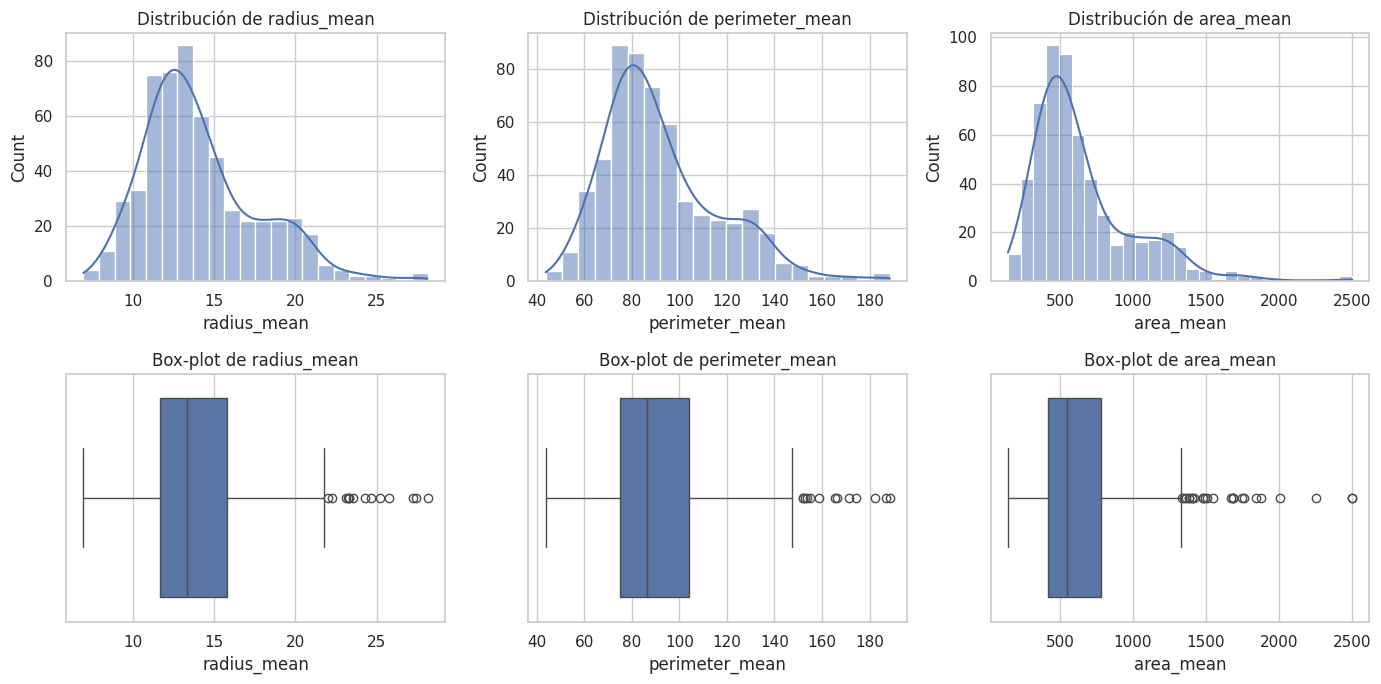

In [ ]:
vars_b1 = ["radius_mean", "perimeter_mean", "area_mean"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, v in enumerate(vars_b1):
    sns.histplot(bc_num[v], kde=True, ax=axes[0, i]); axes[0, i].set_title(f"Distribución de {v}")
    sns.boxplot(x=bc_num[v], ax=axes[1, i]);          axes[1, i].set_title(f"Box-plot de {v}")
plt.tight_layout(); plt.show()

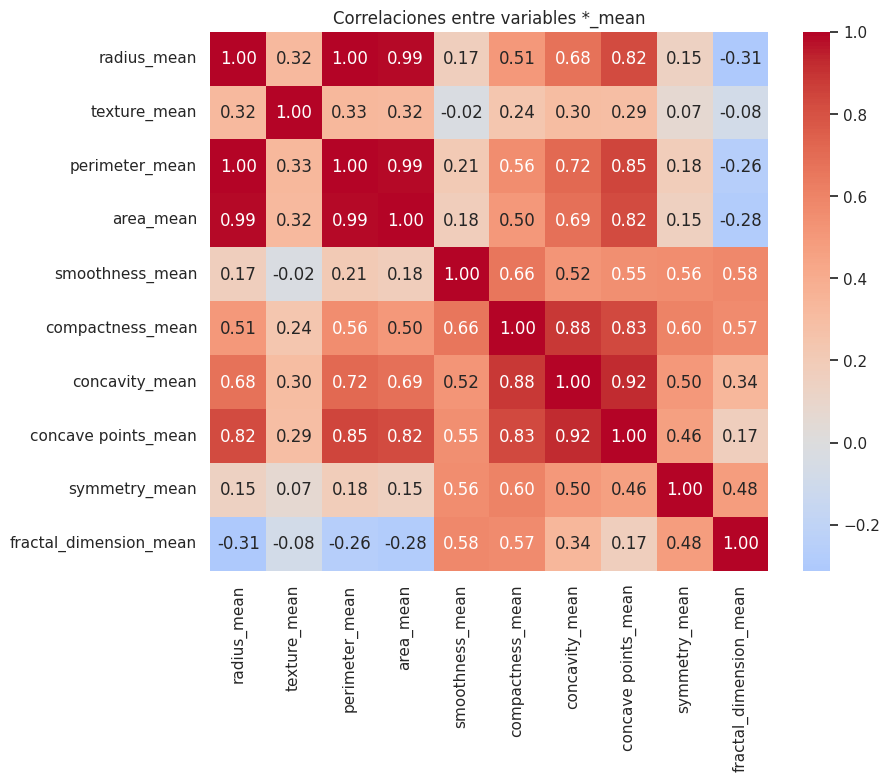

In [ ]:
# Correlaciones entre las variables numéricas (se usan las 10 primeras: *_mean)
cols_mean = [c for c in bc_num.columns if c.endswith("_mean")]
plt.figure(figsize=(9, 7))
sns.heatmap(bc_num[cols_mean].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones entre variables *_mean"); plt.show()

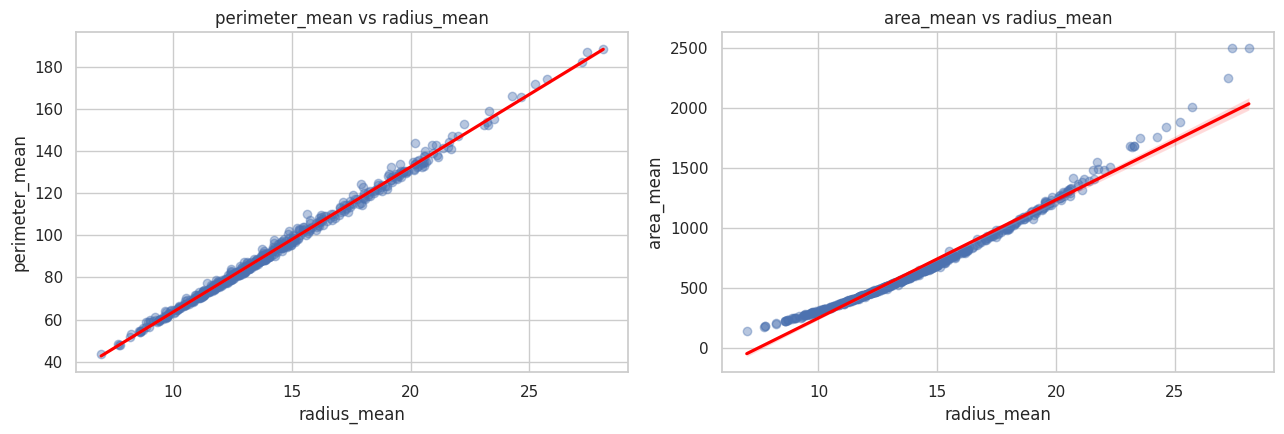

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.regplot(data=bc_num, x="radius_mean", y="perimeter_mean", ax=axes[0], scatter_kws={"alpha": .4}, line_kws={"color": "red"})
axes[0].set_title("perimeter_mean vs radius_mean")
sns.regplot(data=bc_num, x="radius_mean", y="area_mean", ax=axes[1], scatter_kws={"alpha": .4}, line_kws={"color": "red"})
axes[1].set_title("area_mean vs radius_mean")
plt.tight_layout(); plt.show()

**Comentario del EDA:**

Las tres variables (radius_mean, perimeter_mean y area_mean) presentan distribuciones asimétricas hacia la derecha, con valores atípicos solo en el extremo alto, que corresponden a unos pocos núcleos mucho más grandes que el resto. El área es la más asimétrica. En el mapa de correlaciones, radius_mean tiene una correlación de 1.00 con perimeter_mean y de 0.99 con area_mean, lo que es esperable porque las tres miden el tamaño del mismo núcleo. Esto respalda usar radius_mean como predictor en ambos modelos. También indica que las tres serían redundantes si se usaran juntas como predictores.

En el gráfico de perimeter_mean contra radius_mean, los puntos siguen la recta de forma casi perfecta en todo el rango. En el de area_mean, los puntos describen una curva que se dobla hacia arriba: la recta queda por debajo de los puntos en los extremos y por encima en la zona media, e incluso predice valores cercanos a cero o negativos para radios pequeños. Esto tiene sentido geométrico porque el perímetro de un círculo (2πr) crece de forma lineal con el radio, mientras que el área (πr²) crece de forma cuadrática. Por eso, aunque la correlación sea 0.99, una recta no es la forma adecuada para modelar el área.

## 1.3 Modelos y evaluación (partición 80/20)

In [ ]:
def ajustar_simple(X_col, y_col, df):
    X = df[[X_col]]; y = df[y_col]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
    mod = LinearRegression().fit(X_tr, y_tr)
    pred_tr, pred_te = mod.predict(X_tr), mod.predict(X_te)
    return dict(modelo=mod, X_tr=X_tr, X_te=X_te, y_tr=y_tr, y_te=y_te, pred_tr=pred_tr, pred_te=pred_te)

m1 = ajustar_simple("radius_mean", "perimeter_mean", bc_num)   # Modelo 1: perimeter ~ radius
m2 = ajustar_simple("radius_mean", "area_mean", bc_num)        # Modelo 2: area ~ radius

for nombre, m, y in [("Modelo 1: perimeter_mean ~ radius_mean", m1, "perimeter_mean"),
                     ("Modelo 2: area_mean ~ radius_mean", m2, "area_mean")]:
    print(nombre)
    print(f"  Pendiente  : {m['modelo'].coef_[0]:.4f}")
    print(f"  Intercepto : {m['modelo'].intercept_:.4f}\n")

Modelo 1: perimeter_mean ~ radius_mean
  Pendiente  : 6.8640
  Intercepto : -5.0208

Modelo 2: area_mean ~ radius_mean
  Pendiente  : 99.0408
  Intercepto : -743.8449



In [ ]:
tabla_b1 = pd.DataFrame({
    "Modelo 1 (perimeter ~ radius)": metricas(m1["y_te"], m1["pred_te"]),
    "Modelo 2 (area ~ radius)":      metricas(m2["y_te"], m2["pred_te"]),
}).T
tabla_b1.round(4)

,R2,MAE,RMSE
Modelo 1 (perimeter ~ radius),0.9957,1.0424,1.5834
Modelo 2 (area ~ radius),0.9812,34.9748,46.5776


**Interpretación de pendiente e intercepto:**

**Modelo 1 (perimeter ~ radius)**: por cada unidad que aumenta radius_mean, perimeter_mean aumenta en promedio 6.86 unidades. Es cercano a 2π ≈ 6.28, que es lo que se espera si el núcleo fuera un círculo. Queda algo por encima porque los núcleos reales son irregulares y su contorno es más largo que el de un círculo perfecto. El intercepto (-5.02) significa que un radio 0 daría un perímetro negativo, lo cual no tiene sentido físico. Es solo un valor de ajuste de la recta, ya que los datos empiezan en radios cercanos a 7 y no hay observaciones cerca de 0.


**Modelo 2 (area ~ radius)**: por cada unidad que aumenta radius_mean, area_mean aumenta en promedio 99.04 unidades. Es un promedio sobre todo el rango, porque el área no crece a ritmo constante con el radio. El intercepto (-743.84) implica un área negativa para radios pequeños, que es imposible. Esto ya señala que la recta no es la forma adecuada para esta relación.

## 1.4 Visualización: regresión y residuos

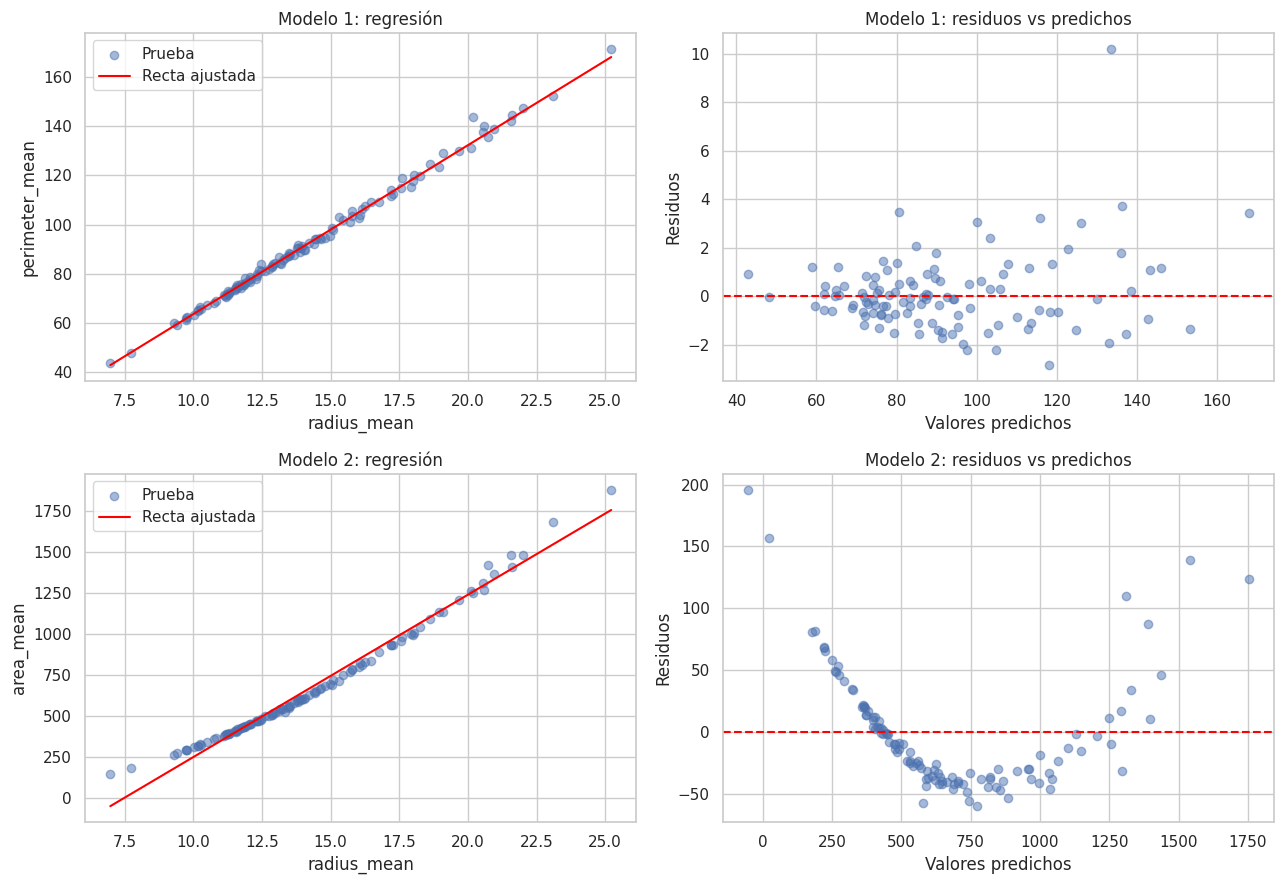

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for fila, (m, y_nombre, titulo) in enumerate([(m1, "perimeter_mean", "Modelo 1"), (m2, "area_mean", "Modelo 2")]):
    # Regresión
    ax = axes[fila, 0]
    ax.scatter(m["X_te"]["radius_mean"], m["y_te"], alpha=.5, label="Prueba")
    orden = np.argsort(m["X_te"]["radius_mean"].values)
    ax.plot(m["X_te"]["radius_mean"].values[orden], m["pred_te"][orden], color="red", label="Recta ajustada")
    ax.set_xlabel("radius_mean"); ax.set_ylabel(y_nombre); ax.set_title(f"{titulo}: regresión"); ax.legend()
    # Residuos
    ax = axes[fila, 1]
    res = m["y_te"].values - m["pred_te"]
    ax.scatter(m["pred_te"], res, alpha=.5)
    ax.axhline(0, color="red", ls="--")
    ax.set_xlabel("Valores predichos"); ax.set_ylabel("Residuos"); ax.set_title(f"{titulo}: residuos vs predichos")
plt.tight_layout(); plt.show()

**Comparación de los gráficos:**

En el modelo 1, los residuos se reparten alrededor de 0 sin ningún patrón, con una dispersión algo mayor en los valores altos y un punto atípico cerca de 10. La recta se ajusta bien a toda la nube. la recta del modelo 2 queda por debajo de los puntos en los radios pequeños y en los grandes, y por encima en la zona media. Eso es consistente con los residuos positivos en los extremos y negativos al centro, porque residuo = real - predicho. Algunas predicciones incluso salen negativas (cerca de -50), lo que es imposible para un área. Es un patrón sistemático y no ruido aleatorio.

**¿un R² alto es suficiente?**

No. Los dos modelos tienen un R² alto (0.9957 y 0.9812), pero solo el primero es adecuado. El R² resume cuánta variación explica la recta, pero no revela si la forma del modelo es correcta. En el modelo 2, el gráfico de residuos muestra una curvatura clara: la relación real entre área y radio es cuadrática (πr²) y una recta no la captura, aunque el R² sea alto. Esto significa que el error del modelo 2 es sistemático y depende del tamaño del tumor, por lo que el modelo no sería confiable en los extremos. Hay que mirar los residuos y no quedarse con el R².

---

# Bloque 2 · Regresión lineal múltiple (EA Sports FC 24)

Dataset: `stefanoleone992/ea-sports-fc-24-complete-player-dataset` (ya que el fifa del aula virtual no esta disponible). este kaggle tiene varios CSV; el principal para jugadores masculinos es 'male_players.csv', que reúne varias ediciones del juego (columna 'fifa_version'). Se trabaja con la edición **24**.

## 2.1 Carga y EDA

In [ ]:
path_fc = kagglehub.dataset_download("stefanoleone992/ea-sports-fc-24-complete-player-dataset")
for root, _, files in os.walk(path_fc):
    for f in files: print(os.path.join(root, f))

100%|██████████| 28.0M/28.0M [00:00<00:00, 137MB/s] 

Extracting files...


/root/.cache/kagglehub/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset/versions/4/male_teams.csv
/root/.cache/kagglehub/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset/versions/4/female_teams.csv
/root/.cache/kagglehub/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset/versions/4/female_players.csv
/root/.cache/kagglehub/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset/versions/4/female_coaches.csv
/root/.cache/kagglehub/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset/versions/4/male_coaches.csv
/root/.cache/kagglehub/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset/versions/4/male_players.csv


In [ ]:
ruta_fc = [os.path.join(r, f) for r, _, fs in os.walk(path_fc) for f in fs if f == "male_players.csv"][0]
fc_raw = pd.read_csv(ruta_fc, low_memory=False)
print("Dimensiones originales:", fc_raw.shape)
print("Ediciones:", sorted(fc_raw["fifa_version"].dropna().unique()))

# Solo FC 24, un registro por jugador (el más reciente)
fc = fc_raw[fc_raw["fifa_version"] == 24].copy()
if "fifa_update" in fc.columns:
    fc = fc.sort_values("fifa_update").drop_duplicates("player_id", keep="last")
fc = fc.dropna(subset=["overall"]).reset_index(drop=True)
print("Dimensiones FC 24:", fc.shape)
fc[["short_name", "player_positions", "overall", "potential", "age"]].head()

Dimensiones originales: (180021, 109)
Ediciones: [np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0)]
Dimensiones FC 24: (18350, 109)


,short_name,player_positions,overall,potential,age
0,K. Mbappé,"ST, LW",91,94,24
1,E. Haaland,ST,91,94,22
2,K. De Bruyne,"CM, CAM",91,91,32
3,L. Messi,"CF, CAM",90,90,36
4,K. Benzema,"CF, ST",90,90,35


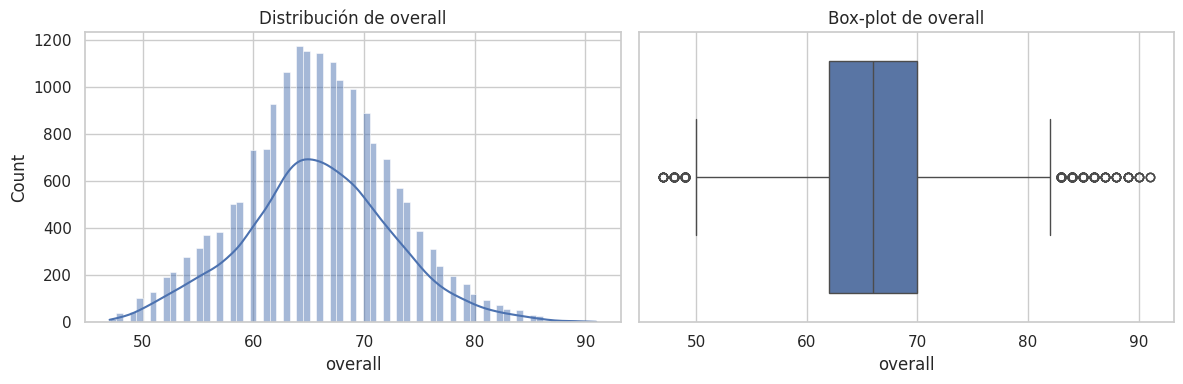

In [ ]:
# Variable objetivo: overall
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(fc["overall"], kde=True, ax=axes[0]); axes[0].set_title("Distribución de overall")
sns.boxplot(x=fc["overall"], ax=axes[1]);          axes[1].set_title("Box-plot de overall")
plt.tight_layout(); plt.show()

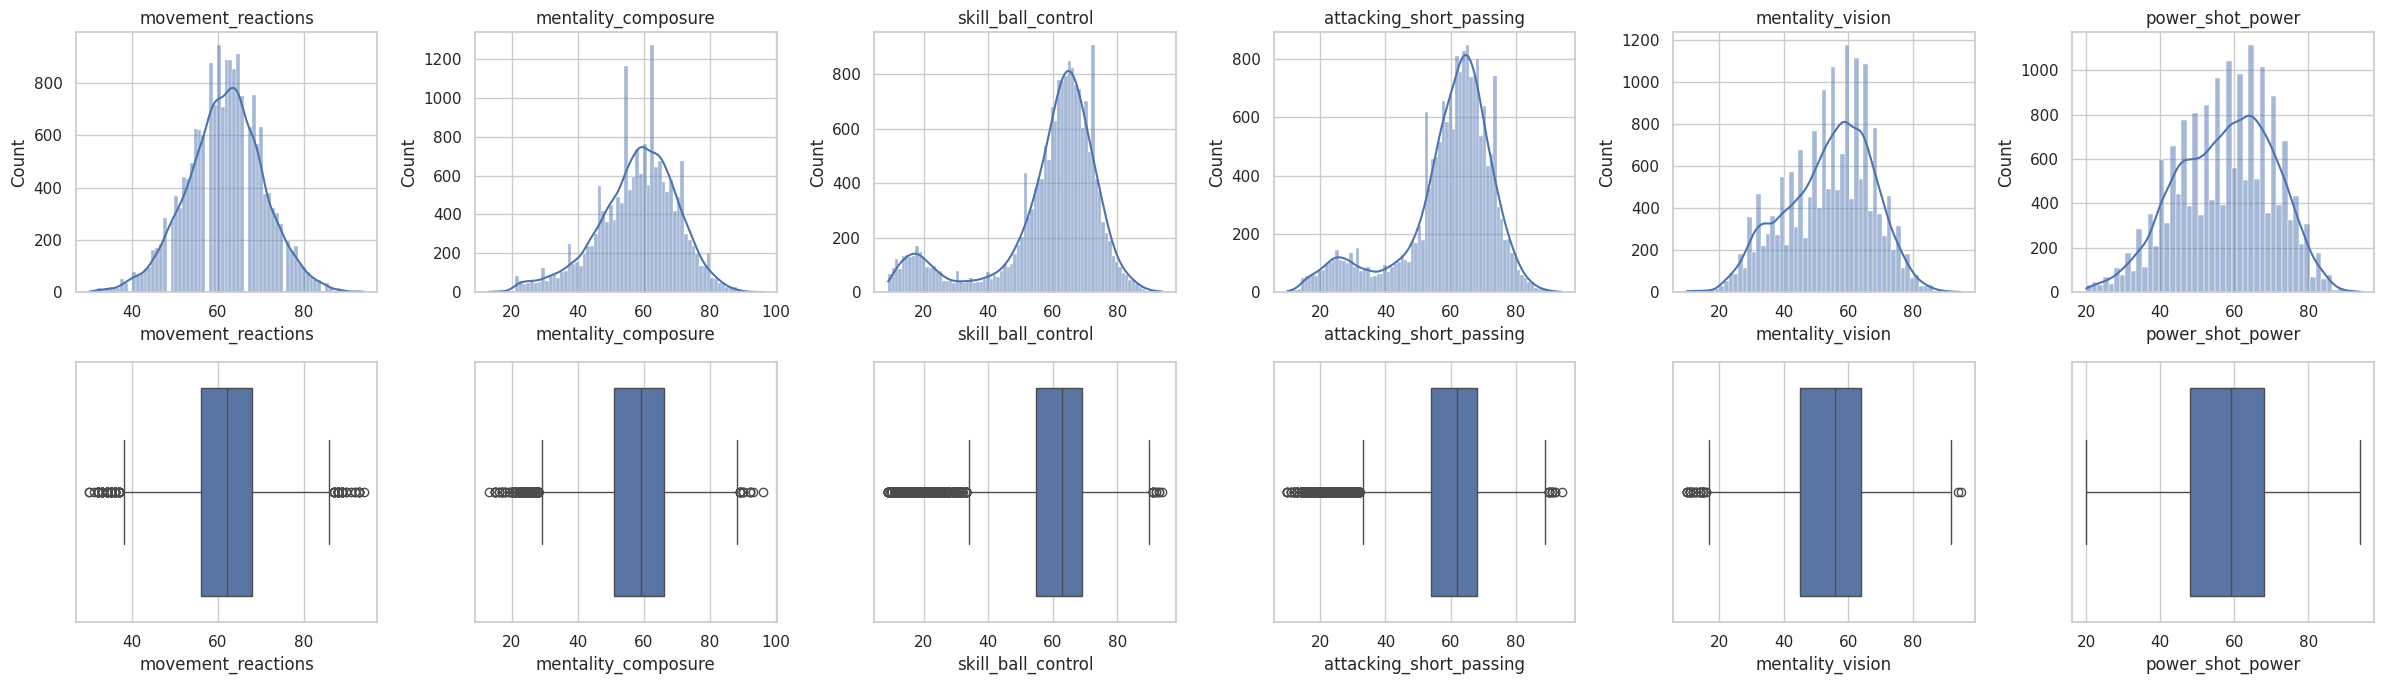

In [ ]:
cand_eda = [c for c in ["movement_reactions", "mentality_composure", "skill_ball_control",
                        "attacking_short_passing", "mentality_vision", "power_shot_power"] if c in fc.columns]
fig, axes = plt.subplots(2, len(cand_eda), figsize=(4 * len(cand_eda), 7))
for i, v in enumerate(cand_eda):
    sns.histplot(fc[v].dropna(), kde=True, ax=axes[0, i]); axes[0, i].set_title(v)
    sns.boxplot(x=fc[v].dropna(), ax=axes[1, i])
plt.tight_layout(); plt.show()

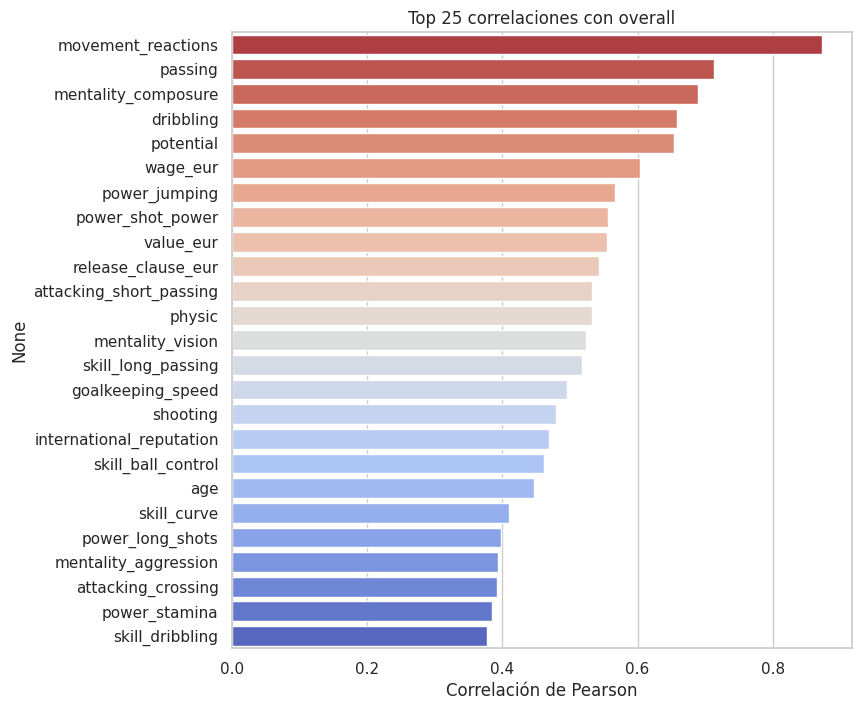

,overall
movement_reactions,0.873
passing,0.713
mentality_composure,0.689
dribbling,0.658
potential,0.653
wage_eur,0.603
power_jumping,0.567
power_shot_power,0.557
value_eur,0.554
release_clause_eur,0.542


In [ ]:
# Correlaciones de todas las variables numéricas con overall
num = fc.select_dtypes(include=np.number).drop(columns=["player_id", "fifa_version", "fifa_update"], errors="ignore")
corr_overall = num.corr()["overall"].drop("overall").sort_values(key=abs, ascending=False)
top = corr_overall.head(25)
plt.figure(figsize=(8, 8))
sns.barplot(x=top.values, y=top.index, palette="coolwarm_r")
plt.title("Top 25 correlaciones con overall"); plt.xlabel("Correlación de Pearson"); plt.show()
corr_overall.head(25).round(3)

**Comentario del EDA:**

La variable objetivo overall tiene una distribución aproximadamente simétrica, con una leve cola hacia la derecha, centrada en torno a 65-66 puntos. La mayoría de los jugadores está entre 62 y 70 según el box-plot. Hay pocos valores atípicos en ambos extremos: unos pocos jugadores bajo 50 y varios sobre 82, que corresponden a las grandes estrellas (por ejemplo Mbappé, Haaland y De Bruyne con 91).

En el gráfico de correlaciones, la variable más relacionada con overall es movement_reactions (0.873), con bastante distancia sobre las siguientes: passing (0.713), mentality_composure (0.689) y dribbling (0.658). Entre las variables técnicas, también destacan attacking_short_passing, mentality_vision y skill_ball_control, todas sobre 0.46.

Al revisar las candidatas, movement_reactions, mentality_composure y mentality_vision tienen distribuciones aproximadamente simétricas. En cambio, skill_ball_control y attacking_short_passing son bimodales, con un grupo pequeño de valores muy bajos que probablemente corresponde a los arqueros, y por eso sus box-plots muestran muchos atípicos inferiores. Estos valores no son errores de datos, sino un subgrupo con un comportamiento distinto, lo que anticipa un problema de heterogeneidad que se revisará más adelante en el modelo.

Varias de las variables más correlacionadas me generan sospecha de fuga de datos: potential (0.653), wage_eur (0.603), value_eur (0.554), release_clause_eur (0.542) e international_reputation (0.469). Salarios, valor de mercado y cláusula de rescisión son consecuencia del nivel del jugador, es decir, se calculan o se fijan a partir de la valoración, y potential se estima junto con overall. Por eso no las usaré como predictores y trabajaré con los atributos técnicos y mentales, que sí existirían antes de conocer la valoración general.

## 2.2 Selección de predictores y data leakage

In [ ]:
# Aplica la pregunta de control a las variables más correlacionadas:
sospechosas = ["potential", "value_eur", "wage_eur", "release_clause_eur", "international_reputation"]
pd.DataFrame({"correlacion_con_overall": corr_overall.reindex(sospechosas)}).round(3)

,correlacion_con_overall
potential,0.653
value_eur,0.554
wage_eur,0.603
release_clause_eur,0.542
international_reputation,0.469


In [ ]:
# Candidatas (>= 8). Ajusta esta lista según TU criterio y el gráfico de correlaciones.
candidatas_deseadas = [
    "movement_reactions", "mentality_composure", "skill_ball_control", "attacking_short_passing",
    "mentality_vision", "power_shot_power", "skill_dribbling", "attacking_finishing",
    "power_stamina", "age", "mentality_positioning", "skill_long_passing"
]
candidatas = [c for c in candidatas_deseadas if c in fc.columns]
print("Candidatas disponibles:", candidatas)
print("\nNulos por candidata:\n", fc[candidatas].isna().sum())

fc_m = fc[candidatas + ["overall", "player_positions", "short_name"]].dropna().reset_index(drop=True)
print("\nFilas para modelar:", len(fc_m))

Candidatas disponibles: ['movement_reactions', 'mentality_composure', 'skill_ball_control', 'attacking_short_passing', 'mentality_vision', 'power_shot_power', 'skill_dribbling', 'attacking_finishing', 'power_stamina', 'age', 'mentality_positioning', 'skill_long_passing']

Nulos por candidata:
 movement_reactions         0
mentality_composure        0
skill_ball_control         0
attacking_short_passing    0
mentality_vision           0
power_shot_power           0
skill_dribbling            0
attacking_finishing        0
power_stamina              0
age                        0
mentality_positioning      0
skill_long_passing         0
dtype: int64

Filas para modelar: 18350


### Registro de decisiones sobre leakage:

Descarto potential porque es una estimación del techo del jugador que EA calcula junto con overall, a partir de su nivel actual. Ambas variables provienen de la misma fuente, y por eso correlaciona 0.653 sin ser un atributo independiente.

Descarto value_eur, wage_eur y release_clause_eur porque son consecuencia directa del nivel del jugador. El valor de mercado, el salario y la cláusula de rescisión se fijan en función de su valoración (correlaciones de 0.554, 0.603 y 0.542). Dejarlas en el modelo sería dar la respuesta como predictor, y esa información no existiría antes de conocer overall.

Descarto también international_reputation (0.469) porque se asigna según el nivel y la fama del jugador, de modo que no es independiente de su valoración.

Mantengo los atributos técnicos, mentales y físicos (movement_reactions, mentality_composure, mentality_vision, power_shot_power, skill_dribbling, attacking_finishing, power_stamina y skill_long_passing) junto con age, porque son mediciones de capacidades del jugador que existen antes de conocer la valoración general y aportan información propia en lugar de derivarse de overall.

## 2.3 Multicolinealidad

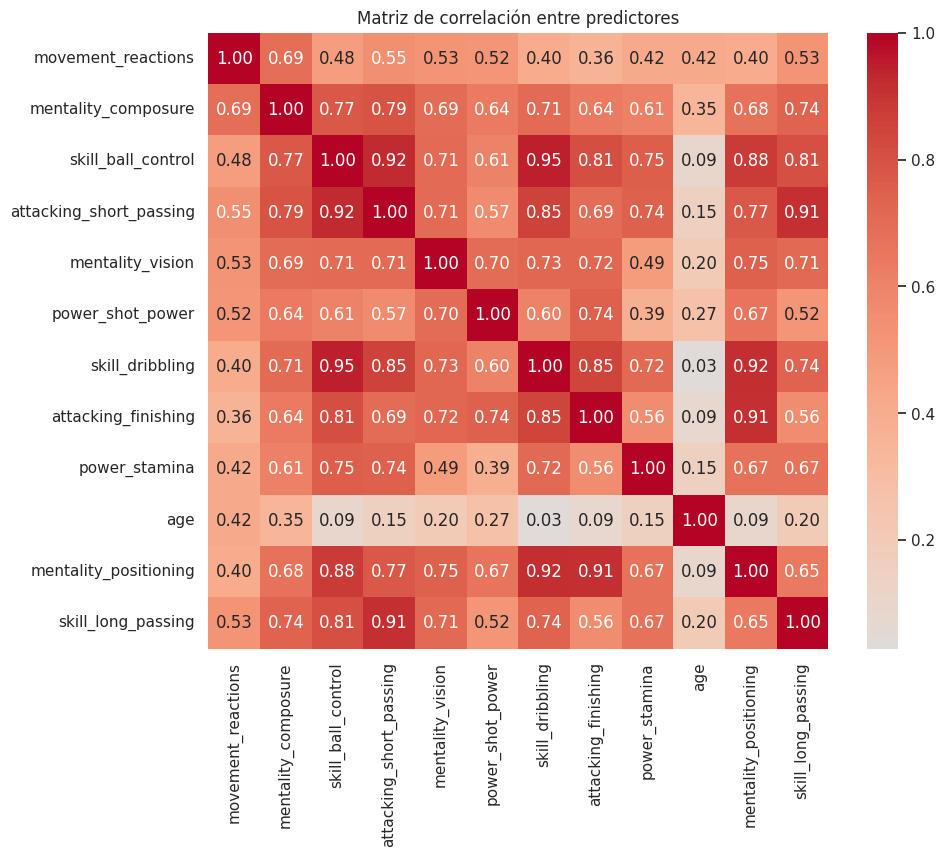

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(fc_m[candidatas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre predictores"); plt.show()

In [ ]:
def calcular_vif(df, cols):
    X = sm.add_constant(df[cols])
    return (pd.DataFrame({"variable": cols,
                          "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]})
            .sort_values("VIF", ascending=False).reset_index(drop=True))

vif_inicial = calcular_vif(fc_m, candidatas)
vif_inicial.round(2)

,variable,VIF
0,skill_ball_control,20.68
1,attacking_short_passing,15.92
2,skill_dribbling,15.25
3,mentality_positioning,11.51
4,attacking_finishing,8.54
5,skill_long_passing,7.88
6,mentality_composure,4.25
7,mentality_vision,3.82
8,power_shot_power,3.14
9,power_stamina,2.71


In [ ]:
# Propuesta automática: eliminar iterativamente la variable con mayor VIF hasta que todas queden <= UMBRAL.
# Es solo una propuesta: tú decides y justificas qué variables mantienes.
UMBRAL = 10
predictores = candidatas.copy()
while True:
    v = calcular_vif(fc_m, predictores)
    if v["VIF"].max() <= UMBRAL or len(predictores) <= 3:
        break
    print(f"Se elimina {v.loc[0, 'variable']} (VIF = {v.loc[0, 'VIF']:.1f})")
    predictores.remove(v.loc[0, "variable"])

print("\nPredictores finales:", predictores)
calcular_vif(fc_m, predictores).round(2)

Se elimina skill_ball_control (VIF = 20.7)
Se elimina attacking_short_passing (VIF = 12.3)
Se elimina mentality_positioning (VIF = 11.5)

Predictores finales: ['movement_reactions', 'mentality_composure', 'mentality_vision', 'power_shot_power', 'skill_dribbling', 'attacking_finishing', 'power_stamina', 'age', 'skill_long_passing']


,variable,VIF
0,skill_dribbling,7.40
1,attacking_finishing,5.98
2,mentality_composure,3.97
3,skill_long_passing,3.66
4,mentality_vision,3.43
5,power_shot_power,3.12
6,power_stamina,2.51
7,movement_reactions,2.25
8,age,1.39


**Decisión sobre multicolinealidad:**

La matriz de correlación muestra pares muy redundantes entre las candidatas: skill_ball_control con skill_dribbling (0.95), con attacking_short_passing (0.92) y con mentality_positioning (0.88), y también skill_dribbling con mentality_positioning (0.92) y attacking_finishing con mentality_positioning (0.91). El VIF inicial lo confirma: skill_ball_control (20.68), attacking_short_passing (15.92), skill_dribbling (15.25) y mentality_positioning (11.51) superan el umbral de 10.

Eliminé en orden skill_ball_control, attacking_short_passing y mentality_positioning, siempre la de mayor VIF en cada paso. Quedaron 9 predictores. En la tabla final el VIF máximo es 7.40 (skill_dribbling), seguido de attacking_finishing (5.98), mientras que el resto queda bajo 4 y age en 1.39.

Al eliminar variables pierdo parte de la información que aportaban. Sin embargo, esas variables medían casi lo mismo que las que se mantuvieron: el VIF de attacking_short_passing bajó de 15.9 a 12.3 solo al quitar skill_ball_control, lo que muestra que la información era redundante. Si las hubiera dejado, el modelo seguiría prediciendo igual de bien, pero los coeficientes serían inestables y podrían cambiar de signo, y no podría interpretarlos como el efecto de cada atributo. Mantengo skill_dribbling y attacking_finishing aunque estén entre 5 y 10, por lo que sus coeficientes deben interpretarse con cuidado.

## 2.4 Modelo múltiple y métricas

In [ ]:
X = fc_m[predictores]; y = fc_m["overall"]
idx_tr, idx_te = train_test_split(fc_m.index, test_size=0.2, random_state=RANDOM_STATE)
X_tr, X_te, y_tr, y_te = X.loc[idx_tr], X.loc[idx_te], y.loc[idx_tr], y.loc[idx_te]

modelo = LinearRegression().fit(X_tr, y_tr)
pred_tr, pred_te = modelo.predict(X_tr), modelo.predict(X_te)

tabla_b2 = pd.DataFrame({"Entrenamiento": metricas(y_tr, pred_tr), "Prueba": metricas(y_te, pred_te)}).T
display(tabla_b2.round(4))

coefs = pd.DataFrame({"variable": predictores, "coeficiente": modelo.coef_}).sort_values("coeficiente", key=abs, ascending=False)
print("Intercepto:", round(modelo.intercept_, 4))
coefs.round(4)

,R2,MAE,RMSE
Entrenamiento,0.8023,2.3827,3.0422
Prueba,0.7960,2.3640,3.0329


Intercepto: 22.2596


,variable,coeficiente
0,movement_reactions,0.5147
3,power_shot_power,0.1049
1,mentality_composure,0.1004
7,age,0.0872
5,attacking_finishing,-0.0655
2,mentality_vision,0.0149
6,power_stamina,-0.0022
8,skill_long_passing,0.0016
4,skill_dribbling,0.0003


**Interpretación de coeficientes:**

Todos los atributos están en una escala de 0 a 99 puntos y overall también está en puntos, así que cada coeficiente se lee como los puntos de overall que cambian al subir en 1 punto ese atributo, manteniendo constantes los demás. El intercepto (22.26) es el overall predicho para un jugador con todos los predictores en 0, que no corresponde a ningún jugador real y solo sirve como valor de ajuste.

El coeficiente de movement_reactions es 0.5147: un punto más de reacciones se asocia con 0.51 puntos más de overall, el efecto más grande del modelo. Es coherente con su correlación de 0.873 y con que sea el atributo que más pesa en la valoración.

El de power_shot_power es 0.1049: un punto más de potencia de tiro se asocia con 0.10 puntos más de overall. El de mentality_composure es 0.1004, un efecto similar. Ambos son mucho menores que el de reacciones.

El de age es 0.0872: cada año adicional de edad se asocia con 0.087 puntos más de overall, es decir, unos 0.9 puntos por cada diez años. La edad tiene unidades distintas (años), así que no es comparable de forma directa con los atributos.

Un caso que merece comentario es attacking_finishing, con coeficiente negativo (-0.0655). No significa que definir mejor baje la valoración. Está muy correlacionada con skill_dribbling (0.85), y su VIF quedó cerca del umbral (5.98), por lo que el modelo reparte el efecto entre ambas y el signo puede invertirse. Por eso conviene interpretar con cautela los coeficientes de las variables que aún conservan multicolinealidad. Algo parecido pasa con mentality_vision, power_stamina, skill_long_passing y skill_dribbling, cuyos coeficientes son casi cero (entre -0.002 y 0.015): su información ya está recogida por otras variables del modelo.

**Comparación entre entrenamiento y prueba:**

El error es prácticamente igual en ambos conjuntos: R² de 0.8023 en entrenamiento y 0.7960 en prueba, MAE de 2.38 y 2.36, RMSE de 3.04 y 3.03. Esa diferencia mínima indica que el modelo no sobreajusta y generaliza bien a jugadores que no vio. Es esperable con una regresión lineal de 9 predictores y más de 14.000 jugadores de entrenamiento. En términos prácticos, el modelo se equivoca en promedio unos 2.4 puntos de overall, y explica cerca del 80% de la variación.

Predictor más correlacionado: movement_reactions


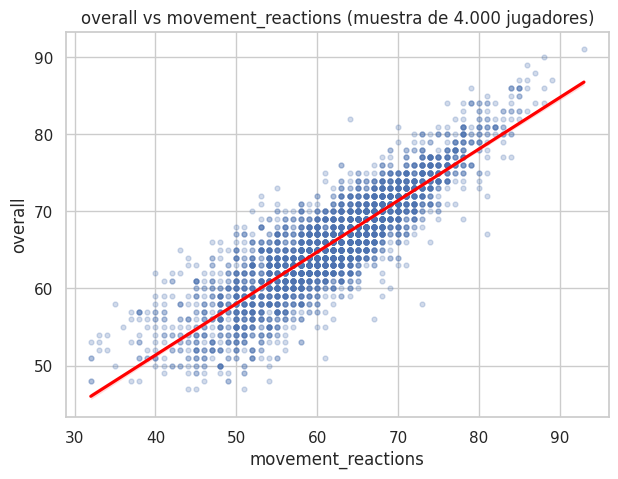

In [ ]:
# Predictor más correlacionado con overall (entre los usados) + recta de regresión
mejor = fc_m[predictores].corrwith(fc_m["overall"]).abs().idxmax()
print("Predictor más correlacionado:", mejor)
muestra = fc_m.sample(min(4000, len(fc_m)), random_state=RANDOM_STATE)
plt.figure(figsize=(7, 5))
sns.regplot(data=muestra, x=mejor, y="overall", scatter_kws={"alpha": .25, "s": 12}, line_kws={"color": "red"})
plt.title(f"overall vs {mejor} (muestra de 4.000 jugadores)"); plt.show()

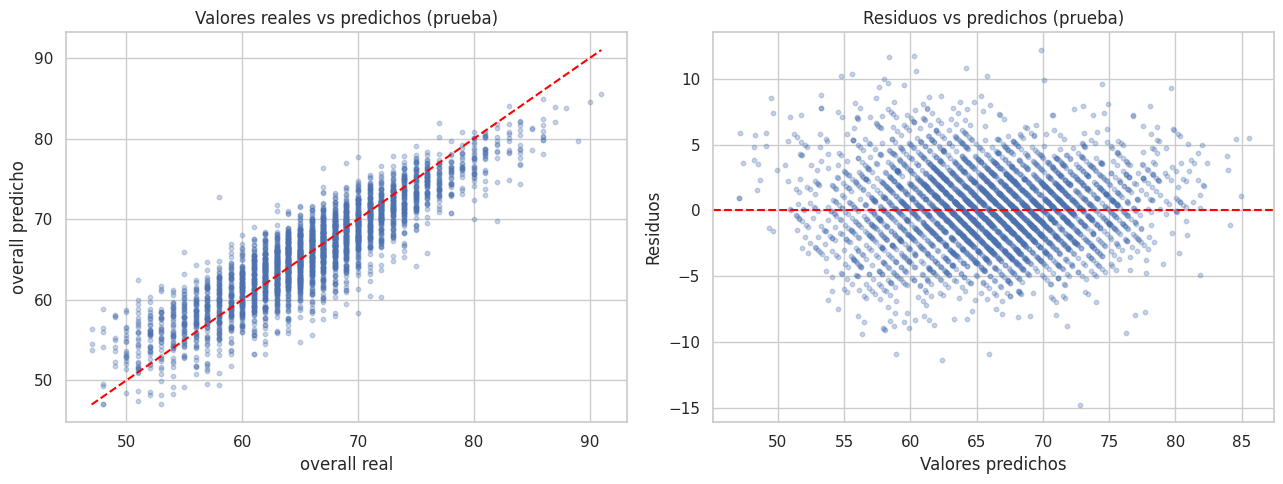

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_te, pred_te, alpha=.3, s=10)
lim = [min(y_te.min(), pred_te.min()), max(y_te.max(), pred_te.max())]
axes[0].plot(lim, lim, color="red", ls="--"); axes[0].set_xlabel("overall real"); axes[0].set_ylabel("overall predicho")
axes[0].set_title("Valores reales vs predichos (prueba)")
axes[1].scatter(pred_te, y_te - pred_te, alpha=.3, s=10); axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Valores predichos"); axes[1].set_ylabel("Residuos"); axes[1].set_title("Residuos vs predichos (prueba)")
plt.tight_layout(); plt.show()

**Comentario de los graficos:**

El predictor más correlacionado, movement_reactions, muestra una relación lineal positiva y clara con overall. La nube sigue la recta de regresión en todo el rango y la dispersión alrededor de ella es similar de un extremo al otro, sin curvatura, lo que respalda usar un modelo lineal.

En el gráfico de valores reales contra predichos, los puntos siguen la diagonal, así que el modelo captura bien la tendencia general. Se nota un sesgo en los extremos: los jugadores de overall bajo (cerca de 50) tienden a quedar por encima de la diagonal, es decir, el modelo los sobreestima, y los de overall alto (sobre 80) quedan por debajo, es decir, los subestima. El modelo comprime las predicciones hacia el centro y no llega a los extremos, algo habitual en la regresión, pero que implica que es menos confiable para los mejores y los peores jugadores.

En el gráfico de residuos contra predichos, los residuos se distribuyen alrededor de cero sin curvatura ni abanico marcado, con una dispersión bastante constante, la mayoría entre -5 y 5 puntos, y algunos casos extremos cercanos a ±10 o más. Esto es coherente con el MAE de 2.4 y el RMSE de 3.0. Las bandas diagonales que se ven son un efecto de que overall es un número entero, no un problema del modelo.

## 2.5 Heterogeneidad por posición

In [ ]:
def grupo_posicion(pos):
    p = str(pos).split(",")[0].strip()
    if p == "GK": return "Arquero"
    if p in ["CB", "LB", "RB", "LWB", "RWB"]: return "Defensa"
    if p in ["CDM", "CM", "CAM", "LM", "RM"]: return "Mediocampista"
    return "Delantero"   # ST, CF, LW, RW

fc_m["grupo"] = fc_m["player_positions"].apply(grupo_posicion)
print(fc_m["grupo"].value_counts())

df_te = fc_m.loc[idx_te].copy()
df_te["pred"] = pred_te
df_te["residuo"] = df_te["overall"] - df_te["pred"]

filas = []
for g, d in df_te.groupby("grupo"):
    m = metricas(d["overall"], d["pred"]); m["n"] = len(d); m["residuo_medio"] = d["residuo"].mean()
    filas.append(pd.Series(m, name=g))
por_grupo = pd.DataFrame(filas)
por_grupo.round(3)

grupo
Mediocampista    6673
Defensa          6174
Delantero        3458
Arquero          2045
Name: count, dtype: int64


,R2,MAE,RMSE,n,residuo_medio
Arquero,0.782,2.751,3.581,445.0,1.264
Defensa,0.794,2.165,2.798,1233.0,0.393
Delantero,0.829,2.221,2.866,721.0,-0.280
Mediocampista,0.781,2.503,3.133,1271.0,-0.524


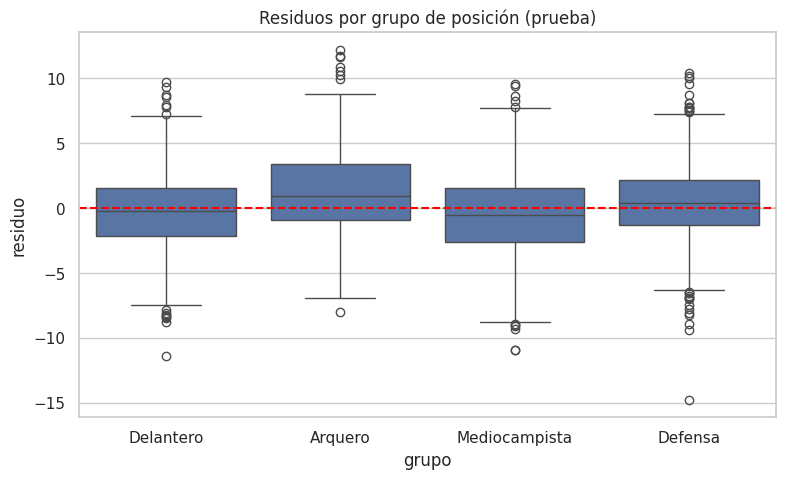

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_te, x="grupo", y="residuo"); plt.axhline(0, color="red", ls="--")
plt.title("Residuos por grupo de posición (prueba)"); plt.show()

**Comparación entre subgrupos:**

El modelo funciona de forma parecida en los cuatro grupos, con un R² entre 0.78 y 0.83, pero el error no se reparte igual. Los arqueros tienen el mayor error medio absoluto (MAE 2.75) y uno de los RMSE más altos (3.58), y es el único grupo con un sesgo claro: su residuo medio es +1.26, lo que significa que el modelo los subestima en promedio más de un punto de overall. El box-plot lo confirma, porque la caja de los arqueros está desplazada hacia arriba y casi no cruza el cero por debajo. Los mediocampistas tienen el peor RMSE (3.13) y un sesgo leve en sentido contrario (-0.52), es decir, se sobreestiman un poco. Los defensas (residuo medio +0.39) y los delanteros (-0.28) quedan casi centrados, y los delanteros tienen el mejor ajuste (R² 0.829).

La conclusión es que el modelo global describe bien a defensas y delanteros, pero es menos confiable para arqueros, por el sesgo, y para mediocampistas, por la mayor dispersión. Un error promedio global de 2.4 puntos oculta que en los arqueros el modelo se equivoca de forma sistemática en una dirección.

**Cosas a tener en cuenta:**


*   Los arqueros tienen solo 445 jugadores en prueba, y la diferencia entre grupos es de decimas de punto. Habla de tendencia y no de una falla grave.
*   Los predictores usados son atributos de campo, y un arquero se valora sobre todo por sus atributos de portería (goalkeeping_*), que no están en el modelo. Es una hipótesis.
*   Como mejora posible, se puede ajustar el modelo por grupo o añadir los atributos de portería para los arqueros.

## 2.6 Desafío opcional: predecir `value_eur`

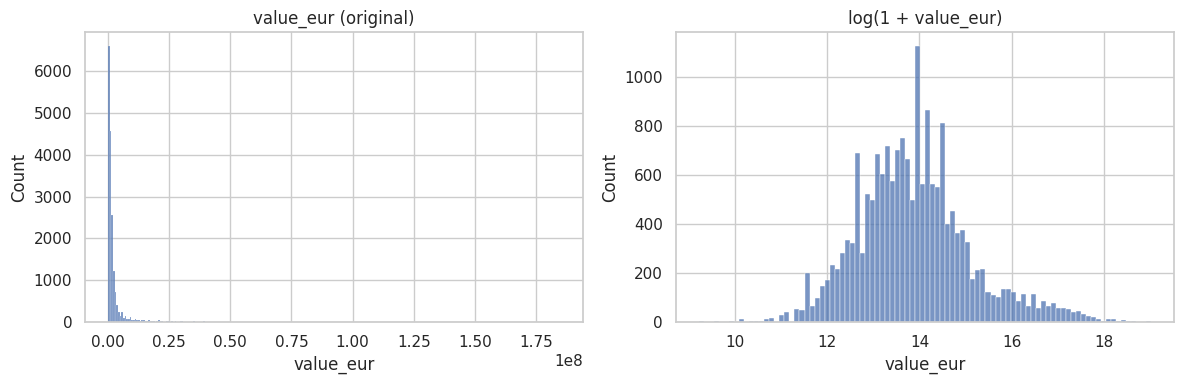

In [ ]:
# En esta edición el valor ya viene numérico (value_eur). Si fuera texto, habría que convertirlo.
v = fc.dropna(subset=["value_eur"]); v = v[v["value_eur"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(v["value_eur"], ax=axes[0]); axes[0].set_title("value_eur (original)")
sns.histplot(np.log1p(v["value_eur"]), ax=axes[1]); axes[1].set_title("log(1 + value_eur)")
plt.tight_layout(); plt.show()

In [ ]:
# Predictores: los mismos del modelo + overall (aquí overall SÍ es un predictor legítimo del valor)
cols_v = predictores + ["overall"]
dv = fc.loc[v.index, cols_v + ["value_eur"]].dropna()
Xv_tr, Xv_te, yv_tr, yv_te = train_test_split(dv[cols_v], dv["value_eur"], test_size=0.2, random_state=RANDOM_STATE)

m_raw = LinearRegression().fit(Xv_tr, yv_tr)
m_log = LinearRegression().fit(Xv_tr, np.log1p(yv_tr))
pred_log = np.expm1(m_log.predict(Xv_te))

print("Sin transformar :", {k: round(x, 3) for k, x in metricas(yv_te, m_raw.predict(Xv_te)).items()})
print("Con log (en €)  :", {k: round(x, 3) for k, x in metricas(yv_te, pred_log).items()})
print("Con log (escala log) R2:", round(r2_score(np.log1p(yv_te), m_log.predict(Xv_te)), 3))

Sin transformar : {'R2': 0.343, 'MAE': 3036111.671, 'RMSE': np.float64(6580248.025)}
Con log (en €)  : {'R2': 0.916, 'MAE': 644314.386, 'RMSE': np.float64(2350258.569)}
Con log (escala log) R2: 0.964


**Conclusión del desafío:** (value_eur)

La distribución original de value_eur es extremadamente asimétrica: la gran mayoría de los jugadores se concentra cerca de valores bajos y unos pocos llegan a decenas o cientos de millones de euros, lo que estira el eje hasta 1.8e8. Un modelo lineal ajustado sobre esta variable tiene un mal desempeño: R² de 0.343, MAE de unos 3.04 millones y RMSE de unos 6.58 millones. Al aplicar el logaritmo, la distribución se vuelve mucho más simétrica y parecida a una campana, y el ajuste mejora de forma notable: al volver a euros, el R² sube a 0.916, el MAE baja a unos 644 mil y el RMSE a unos 2.35 millones. En la escala logarítmica el R² es 0.964. La transformación logarítmica mejora el modelo porque el valor de mercado crece de forma multiplicativa (un jugador de 90 de overall no vale un poco más que uno de 80, sino varias veces más), una relación que una recta no capta sobre euros pero sí sobre su logaritmo.

# Bloque 3 · Transferencia a mi propio dataset

Dataset del Laboratorio 01: **Data Science for COVID-19 (DS4C) · PatientInfo** (pacientes de Corea del Sur).

In [40]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

def metricas(y_real, y_pred):
    return {"R2": r2_score(y_real, y_pred), "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred))}

## 3.1 Carga e inspección

In [43]:
import glob   # en tu notebook principal no está importado

path_pi = kagglehub.dataset_download("kimjihoo/coronavirusdataset")
print(os.listdir(path_pi))   # confirmar los archivos de la carpeta

rutas = glob.glob(os.path.join(path_pi, "**", "*PatientInfo*.csv"), recursive=True)
assert rutas, "No se encontró PatientInfo en la descarga; revisa la lista de archivos de arriba."
pe = pd.read_csv(rutas[0])

print("Archivo:", rutas[0]); print("Dimensiones:", pe.shape)
print(pe.dtypes); print("\nNulos por columna:"); print(pe.isna().sum())
pe.head()

Using Colab cache for faster access to the 'coronavirusdataset' dataset.
['TimeAge.csv', 'Case.csv', 'Policy.csv', 'Region.csv', 'PatientInfo.csv', 'SearchTrend.csv', 'Weather.csv', 'TimeProvince.csv', 'TimeGender.csv', 'SeoulFloating.csv', 'Time.csv']
Archivo: /kaggle/input/coronavirusdataset/PatientInfo.csv
Dimensiones: (5165, 14)
patient_id             int64
sex                   object
age                   object
country               object
province              object
city                  object
infection_case        object
infected_by           object
contact_number        object
symptom_onset_date    object
confirmed_date        object
released_date         object
deceased_date         object
state                 object
dtype: object

Nulos por columna:
patient_id               0
sex                   1122
age                   1380
country                  0
province                 0
city                    94
infection_case         919
infected_by           3819
contact_n

,patient_id,sex,age,country,province,city,infection_case,infected_by,contact_number,symptom_onset_date,confirmed_date,released_date,deceased_date,state
0,1000000001,male,50s,Korea,Seoul,Gangseo-gu,overseas inflow,NaN,75,2020-01-22,2020-01-23,2020-02-05,NaN,released
1,1000000002,male,30s,Korea,Seoul,Jungnang-gu,overseas inflow,NaN,31,NaN,2020-01-30,2020-03-02,NaN,released
2,1000000003,male,50s,Korea,Seoul,Jongno-gu,contact with patient,2002000001,17,NaN,2020-01-30,2020-02-19,NaN,released
3,1000000004,male,20s,Korea,Seoul,Mapo-gu,overseas inflow,NaN,9,2020-01-26,2020-01-30,2020-02-15,NaN,released
4,1000000005,female,20s,Korea,Seoul,Seongbuk-gu,contact with patient,1000000002,2,NaN,2020-01-31,2020-02-24,NaN,released


## 3.2 Variable objetivo

El dataset **no trae una variable numérica continua lista para usar** la mejor de todas seria:

`dias_a_alta = released_date − confirmed_date` (días entre la confirmación y el alta).

Se eligió dias_a_alta por un motivo práctico: es la mejor variable numérica continua que se puede construir con este dataset.

In [44]:
for c in ["confirmed_date", "released_date", "symptom_onset_date", "deceased_date"]:
    pe[c] = pd.to_datetime(pe[c], errors="coerce")
pe["dias_a_alta"] = (pe["released_date"] - pe["confirmed_date"]).dt.days

base = pe.dropna(subset=["dias_a_alta", "age", "sex"]).copy()
print("Pacientes con alta registrada:", pe["dias_a_alta"].notna().sum(), "| con edad y sexo:", len(base))
print("Valores negativos:", (base["dias_a_alta"] < 0).sum())

# Variables numéricas / indicadoras
base["age_n"] = base["age"].str.replace("s", "").astype(int)            # límite inferior de la década
base["male"] = (base["sex"] == "male").astype(int)
base["conf_dia"] = (base["confirmed_date"] - base["confirmed_date"].min()).dt.days   # día de la epidemia
base["gyeongsangbuk"] = (base["province"] == "Gyeongsangbuk-do").astype(int)

def grupo_contagio(x):
    if pd.isna(x): return "desconocido"
    if x == "contact with patient": return "contacto_paciente"
    if x == "overseas inflow": return "importado"
    if x == "Shincheonji Church": return "shincheonji"
    return "otro_foco"
base["grupo_contagio"] = base["infection_case"].apply(grupo_contagio)
dummies = pd.get_dummies(base["grupo_contagio"], prefix="ic", drop_first=True).astype(int)   # referencia: contacto_paciente
base = pd.concat([base, dummies], axis=1)
print(base["grupo_contagio"].value_counts())

Pacientes con alta registrada: 1587 | con edad y sexo: 1576
Valores negativos: 0
grupo_contagio
desconocido          574
otro_foco            459
contacto_paciente    311
importado            183
shincheonji           49
Name: count, dtype: int64


## 3.3 EDA propio

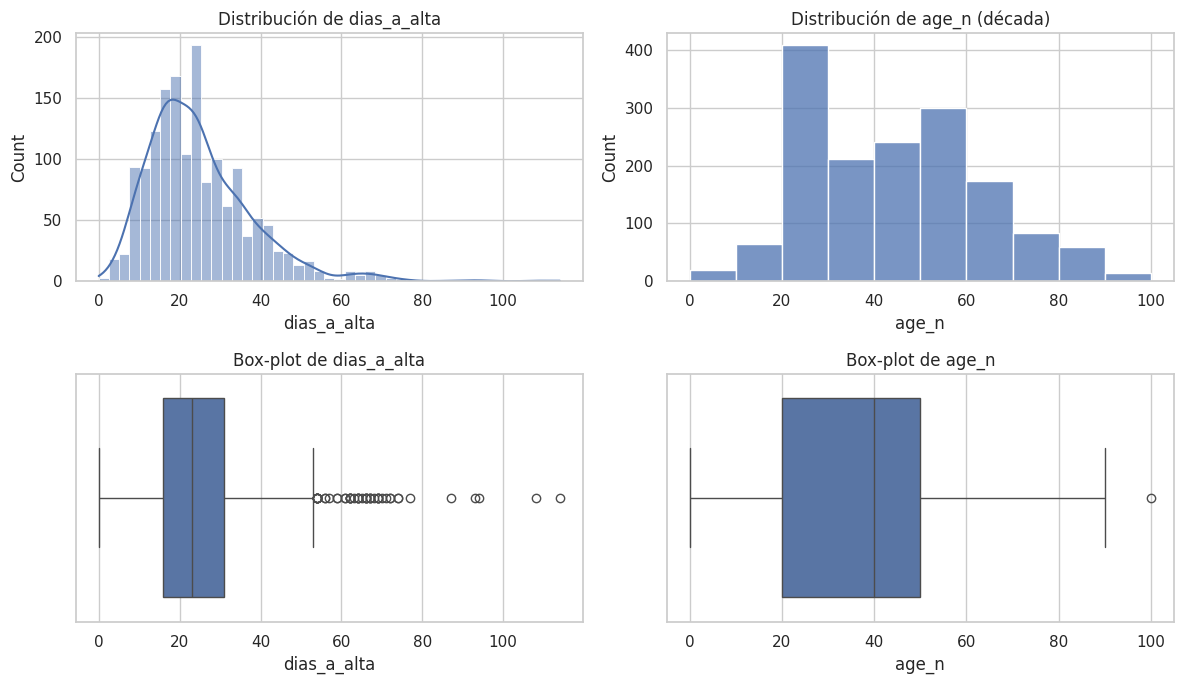

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
sns.histplot(base["dias_a_alta"], kde=True, ax=axes[0, 0]); axes[0, 0].set_title("Distribución de dias_a_alta")
sns.boxplot(x=base["dias_a_alta"], ax=axes[1, 0]);          axes[1, 0].set_title("Box-plot de dias_a_alta")
sns.histplot(base["age_n"], bins=10, ax=axes[0, 1]);        axes[0, 1].set_title("Distribución de age_n (década)")
sns.boxplot(x=base["age_n"], ax=axes[1, 1]);                axes[1, 1].set_title("Box-plot de age_n")
plt.tight_layout(); plt.show()

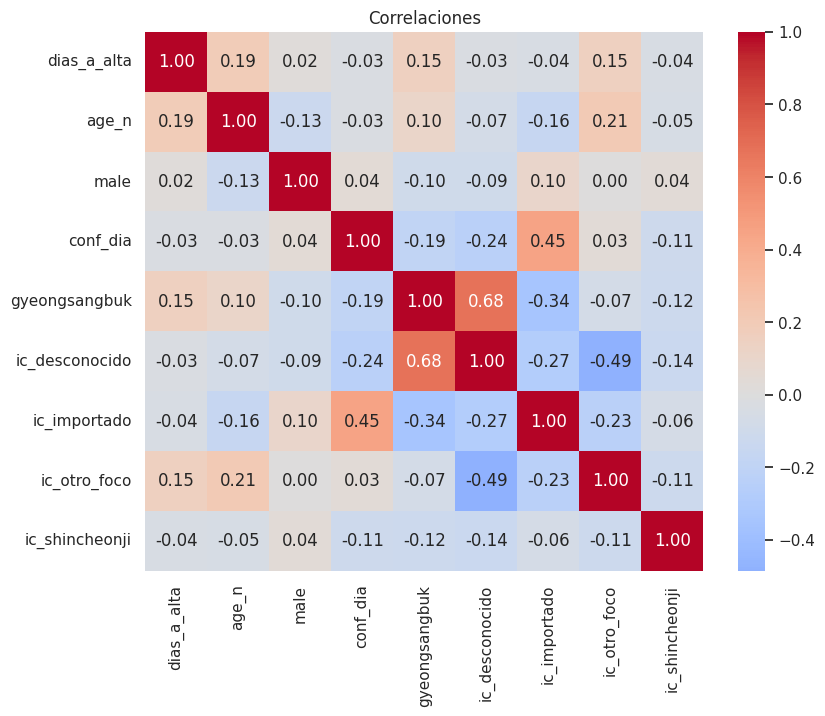

age_n             0.191
ic_otro_foco      0.152
gyeongsangbuk     0.148
ic_importado     -0.042
ic_shincheonji   -0.041
ic_desconocido   -0.032
conf_dia         -0.032
male              0.017
Name: dias_a_alta, dtype: float64


In [46]:
cols_num = ["dias_a_alta", "age_n", "male", "conf_dia", "gyeongsangbuk"] + list(dummies.columns)
plt.figure(figsize=(9, 7))
sns.heatmap(base[cols_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones"); plt.show()
print(base[cols_num].corr()["dias_a_alta"].drop("dias_a_alta").sort_values(key=abs, ascending=False).round(3))

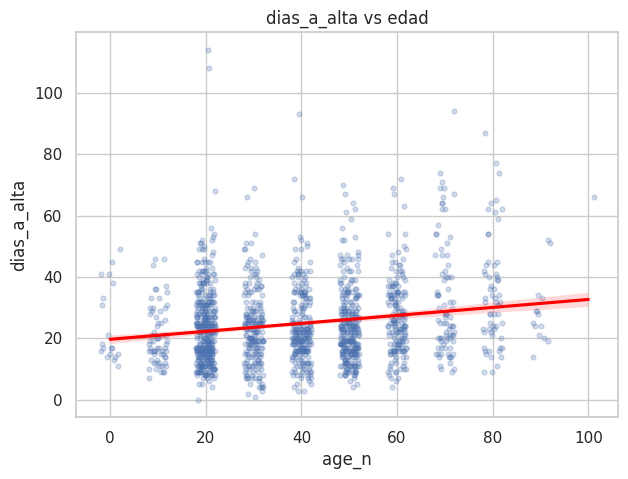

In [47]:
plt.figure(figsize=(7, 5))
sns.regplot(data=base, x="age_n", y="dias_a_alta", x_jitter=2, scatter_kws={"alpha": .25, "s": 12}, line_kws={"color": "red"})
plt.title("dias_a_alta vs edad"); plt.show()

**Comentario del EDA:** `dias_a_alta` tiene una distribución asimétrica a la derecha,
con la mayoría de los pacientes entre ≈ 16 y ≈ 31 días (mediana ≈ 23) y una cola de
casos atípicos que llegan a más de 100 días. La edad (como década) se concentra entre
los 20 y los 60 años. Las correlaciones de las variables con `dias_a_alta` son débiles:
la mayor es la edad (r ≈ 0.19), seguida del foco de contagio "otro foco" (≈ 0.15) y
residir en Gyeongsangbuk-do (≈ 0.15). El gráfico de regresión muestra una tendencia
positiva leve (≈ 1.3 días más por década), pero con una dispersión muy grande en cada
edad. Esto sugiere que el modelo tendrá una capacidad predictiva baja. Entre los
predictores, `gyeongsangbuk` e `ic_desconocido` están correlacionados (r ≈ 0.68), lo que
se revisa en la sección de multicolinealidad.

## 3.4 Selección de predictores (data leakage)

**Pregunta de control:** ¿existe esta variable al momento de la confirmación, antes de
saber cuándo se da de alta al paciente? ¿Se calcula a partir de la variable objetivo o
proviene de la misma fuente?

| Variable | ¿Se usa? | Justificación |
|---|---|---|
| `released_date` | No | Es parte de la definición del objetivo (`dias_a_alta = released_date − confirmed_date`): fuga directa. |
| `deceased_date`, `state` | No | Describen el desenlace del paciente (alta, fallecimiento, aislamiento), que ocurre después de la confirmación y es consecuencia del proceso que se quiere predecir. |
| `symptom_onset_date` | No | Existiría al confirmar, por lo que no es fuga, pero falta en ≈ 87 % de los pacientes (4.475 de 5.165); usarla dejaría muy pocos casos. |
| `contact_number` | No | Se registra en la investigación epidemiológica posterior a la confirmación, por lo que no está claro que exista al predecir, y falta en ≈ 85 % de los casos. |
| `infected_by` | No | Falta en ≈ 74 % (3.819) y es el identificador de otro paciente, no una magnitud numérica. |
| `patient_id` | No | Solo identificador, sin significado predictivo. |
| `city` | No | Demasiadas categorías con pocos pacientes cada una; la zona geográfica ya se aproxima con `gyeongsangbuk`. |
| `age_n` | Sí | La edad se conoce al confirmar el caso. |
| `male` | Sí | El sexo se conoce al confirmar el caso. |
| `conf_dia` | Sí | Día de la epidemia en que se confirma: se conoce al confirmar, y puede reflejar cambios en el protocolo hospitalario. |
| `gyeongsangbuk` | Sí | La provincia de residencia se conoce al confirmar. |
| Grupo de contagio (`ic_*`) | Sí | El foco de contagio se registra al confirmar; los casos sin dato quedan en la categoría "desconocido". La categoría de referencia es `contacto_paciente`. |

**Predictores finales (8):** `age_n`, `male`, `conf_dia`, `gyeongsangbuk`, `ic_desconocido`,
`ic_importado`, `ic_otro_foco`, `ic_shincheonji`.

## 3.5 Multicolinealidad

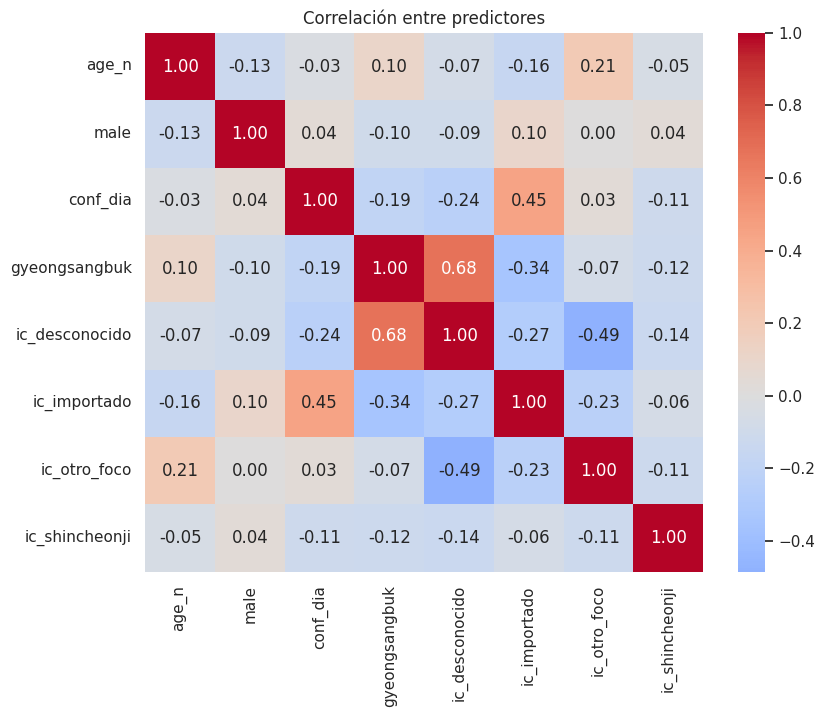

,variable,VIF
0,ic_desconocido,3.47
1,gyeongsangbuk,2.30
2,ic_otro_foco,2.02
3,ic_importado,1.67
4,conf_dia,1.30
5,ic_shincheonji,1.14
6,age_n,1.10
7,male,1.03


In [48]:
predictores = ["age_n", "male", "conf_dia", "gyeongsangbuk"] + list(dummies.columns)
plt.figure(figsize=(9, 7))
sns.heatmap(base[predictores].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre predictores"); plt.show()

def calcular_vif(df, cols):
    X = sm.add_constant(df[cols].astype(float))
    return (pd.DataFrame({"variable": cols, "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]})
            .sort_values("VIF", ascending=False).reset_index(drop=True))
calcular_vif(base, predictores).round(2)

**Decisión sobre multicolinealidad:**


En la matriz de correlación, la pareja más
correlacionada es `gyeongsangbuk` con `ic_desconocido` (r ≈ 0.68); le siguen `conf_dia`
con `ic_importado` (≈ 0.45) e `ic_desconocido` con `ic_otro_foco` (≈ −0.49, esperable
porque son categorías excluyentes del mismo grupo de contagio). Sin embargo, el VIF
más alto es 3.47 (`ic_desconocido`), seguido de `gyeongsangbuk` (2.30), y todos los
demás están por debajo de 2.1. Como ninguno supera el umbral de alerta de 5–10 indicado
en la guía, **mantengo las 8 variables**. Aun así, la correlación de 0.68 indica que los
coeficientes de `gyeongsangbuk` e `ic_desconocido` deben interpretarse con cautela, ya
que comparten parte de su información. Las variables `ic_*` son indicadoras con
`contacto_paciente` como categoría de referencia (se omitió una categoría para evitar
colinealidad perfecta).

## 3.6 Modelo, métricas y residuos

In [49]:
X = base[predictores].astype(float); y = base["dias_a_alta"]
idx_tr, idx_te = train_test_split(base.index, test_size=0.2, random_state=RANDOM_STATE)
X_tr, X_te, y_tr, y_te = X.loc[idx_tr], X.loc[idx_te], y.loc[idx_tr], y.loc[idx_te]
modelo = LinearRegression().fit(X_tr, y_tr)
pred_tr, pred_te = modelo.predict(X_tr), modelo.predict(X_te)

display(pd.DataFrame({"Entrenamiento": metricas(y_tr, pred_tr), "Prueba": metricas(y_te, pred_te)}).T.round(4))
print("Intercepto:", round(modelo.intercept_, 4))
pd.DataFrame({"variable": predictores, "coeficiente": modelo.coef_}).sort_values("coeficiente", key=abs, ascending=False).round(4)

,R2,MAE,RMSE
Entrenamiento,0.0883,9.4467,12.733
Prueba,0.0369,9.0839,11.528


Intercepto: 19.3005


,variable,coeficiente
3,gyeongsangbuk,6.8204
4,ic_desconocido,-3.7876
6,ic_otro_foco,2.9530
5,ic_importado,2.4404
7,ic_shincheonji,-2.0423
1,male,1.4212
0,age_n,0.0971
2,conf_dia,-0.0418


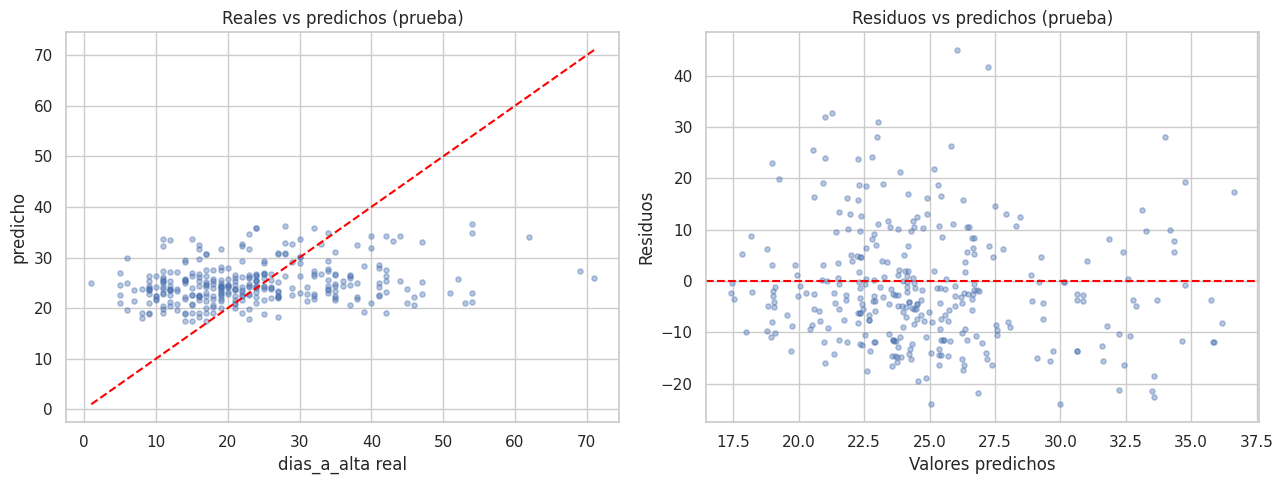

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_te, pred_te, alpha=.4, s=14)
lim = [min(y_te.min(), pred_te.min()), max(y_te.max(), pred_te.max())]
axes[0].plot(lim, lim, color="red", ls="--"); axes[0].set_xlabel("dias_a_alta real"); axes[0].set_ylabel("predicho")
axes[0].set_title("Reales vs predichos (prueba)")
axes[1].scatter(pred_te, y_te - pred_te, alpha=.4, s=14); axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Valores predichos"); axes[1].set_ylabel("Residuos"); axes[1].set_title("Residuos vs predichos (prueba)")
plt.tight_layout(); plt.show()

## 3.7 Heterogeneidad


Segmentación por sex


,R2,MAE,RMSE,n,residuo_medio
female,0.066,9.413,11.899,181.0,-0.815
male,-0.014,8.642,11.010,135.0,-2.064



Segmentación por grupo_edad


,R2,MAE,RMSE,n,residuo_medio
<40,-0.016,8.180,10.742,139.0,-0.769
40-59,-0.189,8.708,10.731,109.0,-3.524
60+,0.051,11.535,14.040,68.0,0.952



Segmentación por region


,R2,MAE,RMSE,n,residuo_medio
Gyeongsangbuk-do,0.043,9.057,11.247,161.0,-2.334
Resto del país,0.009,9.112,11.813,155.0,-0.325


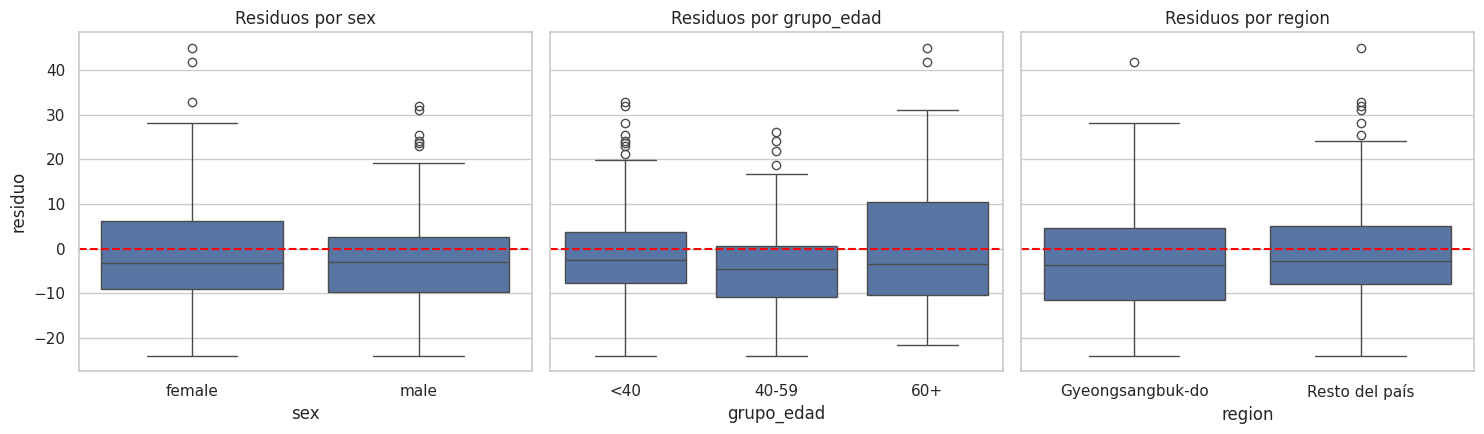

In [51]:
df_te = base.loc[idx_te].copy()
df_te["pred"] = pred_te; df_te["residuo"] = df_te["dias_a_alta"] - df_te["pred"]
df_te["grupo_edad"] = pd.cut(df_te["age_n"], [-1, 39, 59, 200], labels=["<40", "40-59", "60+"])
df_te["region"] = np.where(df_te["gyeongsangbuk"] == 1, "Gyeongsangbuk-do", "Resto del país")

def por_grupo(col):
    filas = []
    for g, d in df_te.groupby(col, observed=True):
        m = metricas(d["dias_a_alta"], d["pred"]); m["n"] = len(d); m["residuo_medio"] = d["residuo"].mean()
        filas.append(pd.Series(m, name=str(g)))
    return pd.DataFrame(filas).round(3)

for col in ["sex", "grupo_edad", "region"]:
    print("\nSegmentación por", col); display(por_grupo(col))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, col in zip(axes, ["sex", "grupo_edad", "region"]):
    sns.boxplot(data=df_te, x=col, y="residuo", ax=ax); ax.axhline(0, color="red", ls="--"); ax.set_title(f"Residuos por {col}")
plt.tight_layout(); plt.show()

**Comentario de heterogeneidad:** El modelo falla más en los pacientes de **60 años o más**
(MAE ≈ 11.5 y RMSE ≈ 14.0 días, contra ≈ 8.2–8.7 y ≈ 10.7 en los otros grupos), aunque es
el grupo con menos pacientes en prueba (n = 68), por lo que esa cifra es menos estable.
En el grupo de **40–59 años** el R² es negativo (≈ −0.19) y el residuo medio es el más
negativo (≈ −3.5 días): el modelo sobreestima sistemáticamente su tiempo de alta. Por
sexo, las métricas son parecidas (RMSE ≈ 11.9 en mujeres y ≈ 11.0 en hombres), y por
región el rendimiento es similar, con un sesgo algo mayor en Gyeongsangbuk-do (residuo
medio ≈ −2.3 vs −0.3). En casi todos los subgrupos el R² es cercano a cero o negativo,
así que el modelo no describe bien a ninguno; el error promedio global oculta que falla
más en los mayores de 60 y que tiende a sobrestimar en el resto.

**(a) Interpreta un coeficiente de tu modelo indicando sus unidades.**

El coeficiente de `gyeongsangbuk` es ≈ 6.82: un paciente de Gyeongsangbuk-do tiene, en
promedio, ≈ 6.8 días más entre la confirmación y el alta que un paciente de otra
provincia, manteniendo constantes las demás variables. La unidad es días de `dias_a_alta`
por el paso de 0 a 1 de una variable indicadora. Debe leerse con cautela porque
`gyeongsangbuk` está correlacionada con `ic_desconocido` (r ≈ 0.68; su coeficiente es
≈ −3.79), de modo que parte de la información se comparte entre ambas. Otro ejemplo: el
coeficiente de `age_n` (≈ 0.097) indica ≈ 0.1 días más por cada año de edad, es decir,
≈ 1 día por década, manteniendo lo demás constante.

**(b) Compara el error en entrenamiento y en prueba y explica qué indica esa diferencia.**

En entrenamiento: R² = 0.088, MAE = 9.45 y RMSE = 12.73. En prueba: R² = 0.037,
MAE = 9.08 y RMSE = 11.53. Las diferencias son pequeñas y el error de prueba es incluso
algo menor, por lo que no hay sobreajuste. El problema es el contrario: el R² es muy
bajo en ambos conjuntos, es decir, el modelo ajusta poco incluso a los datos con los que
se entrenó (subajuste). Las variables disponibles (edad, sexo, región, foco de contagio y
día de la epidemia) explican menos del 10 % de la variabilidad de `dias_a_alta`. Un MAE
de ≈ 9 días es grande frente a un tiempo típico de ≈ 23 días. Que el error de prueba sea
algo menor puede deberse a que, con una partición aleatoria de ≈ 316 pacientes, algunos
casos extremos (altas muy tardías) quedaron en entrenamiento.

**(c) Identifica un supuesto de la regresión lineal que tu modelo cumple o incumple,
con evidencia gráfica.**

El modelo **incumple el supuesto de normalidad (y simetría) de los residuos**. En el
gráfico de residuos vs. predichos, los residuos positivos llegan hasta ≈ +45 días,
mientras que los negativos no bajan de ≈ −24; los box-plots por grupo muestran medianas
por debajo de cero y valores atípicos solo hacia arriba. Esa asimetría proviene de la
distribución sesgada a la derecha de `dias_a_alta`. En el gráfico de reales vs.
predichos, las predicciones quedan en un rango estrecho (≈ 18–37 días) mientras que los
valores reales llegan hasta ≈ 70, por lo que el modelo no capta la variabilidad. En
cambio, no se observa una curva clara en los residuos, por lo que el supuesto de
linealidad no parece claramente violado.

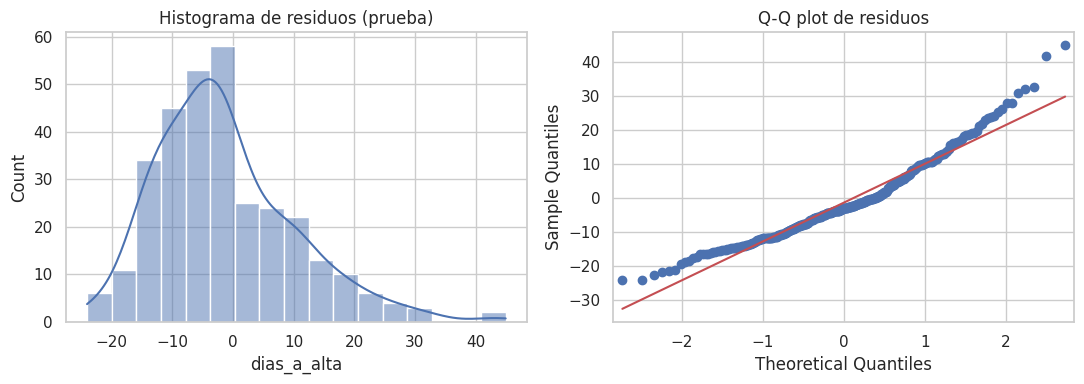

In [52]:
res = y_te - pred_te
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(res, kde=True, ax=axes[0]); axes[0].set_title("Histograma de residuos (prueba)")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Q-Q plot de residuos")
plt.tight_layout(); plt.show()